In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import data_loaders
import miscellaneous
from rs_algorithm.models import RegressionBasedBPEModel
from rs_algorithm.models import AdaptiveRepresentation
from dl_trainer import Trainer, split_collate

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [6]:
try:
    ds = data_model.get_bpr_dataset()
except:
    traceback.print_exc()

In [45]:
try:
    for col in data_model.user_features.columns:
        print(col)
except:
    traceback.print_exc()

user_active_degree_UNKNOWN
user_active_degree_full_active
user_active_degree_high_active
user_active_degree_middle_active
follow_user_num
follow_user_num_range_(0,10]
follow_user_num_range_(10,50]
follow_user_num_range_(100,150]
follow_user_num_range_(150,250]
follow_user_num_range_(250,500]
follow_user_num_range_(50,100]
follow_user_num_range_0
follow_user_num_range_500+
fans_user_num
fans_user_num_range_0
fans_user_num_range_[1,10)
fans_user_num_range_[10,100)
fans_user_num_range_[100,1k)
fans_user_num_range_[1k,5k)
fans_user_num_range_[1w,10w)
fans_user_num_range_[5k,1w)
friend_user_num
friend_user_num_range_0
friend_user_num_range_250+
friend_user_num_range_[1,5)
friend_user_num_range_[120,250)
friend_user_num_range_[30,60)
friend_user_num_range_[5,30)
friend_user_num_range_[60,120)
register_days
register_days_range_15-30
register_days_range_181-365
register_days_range_31-60
register_days_range_366-730
register_days_range_61-90
register_days_range_730+
register_days_range_91-180
on

In [43]:
try:
    for col in data_model.user_features.columns:
        dat = data_model.user_features[col]
        print(f"{col:40s}", dat.min(), dat.max(), dat.mean(), dat.std())
except:
    traceback.print_exc()

user_active_degree_UNKNOWN               False True 0.01644370122630992 0.12718317512777091
user_active_degree_full_active           False True 0.8489409141583054 0.35813141670387977
user_active_degree_high_active           False True 0.13071348940914157 0.3371102337177617
user_active_degree_middle_active         False True 0.0039018952062430325 0.0623475109067581
follow_user_num                          -0.4626210845907247 4.460678077746371 3.762628756812125e-17 1.0
follow_user_num_range_(0,10]             False True 0.27020624303233 0.44409718852811947
follow_user_num_range_(10,50]            False True 0.3068561872909699 0.4612213260245352
follow_user_num_range_(100,150]          False True 0.059921962095875136 0.23735874032692625
follow_user_num_range_(150,250]          False True 0.06577480490523968 0.24790531295838195
follow_user_num_range_(250,500]          False True 0.0636845039018952 0.24420708117726586
follow_user_num_range_(50,100]           False True 0.12402452619843925 0

In [46]:
try:
    for i, d in zip(range(1), ds):
        print("Sample")
        print(len(d))
        print(len(d[0]), type(d[0][0]), type(d[0][1]), type(d[0][2]), type(d[0][3]), type(d[0][4]), type(d[0][5]))
        print(len(d[1]), type(d[1][0]), type(d[1][1]))
        ...
except:
    traceback.print_exc()

Sample
2
6 <class 'numpy.int64'> <class 'numpy.ndarray'> <class 'numpy.int64'> <class 'numpy.ndarray'> <class 'numpy.int64'> <class 'numpy.ndarray'>
2 <class 'numpy.float32'> <class 'numpy.float32'>


In [18]:
try:
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=1024, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=1024, id2idx=iid2idx)
    model = RegressionBasedBPEModel(user_model, item_model)
except:
    traceback.print_exc()

In [63]:
try:
    ...
except:
    traceback.print_exc()

In [19]:
def loss_fn_all(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds

    # is it really necessary?
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)

    # regression
    reg_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)

    # ranking
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))

    # weight by preference strength
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()

    return reg_loss + rank_loss


def loss_fn_al_v2(preds, truth, lambda_reg=1.0, lambda_rank=1.0):
    s_pos, s_neg = preds
    r_pos, r_neg = truth

    r_pos_t = torch.log1p(r_pos)
    r_neg_t = torch.log1p(r_neg)

    reg_loss = F.mse_loss(s_pos, r_pos_t) + F.mse_loss(s_neg, r_neg_t)

    diff = s_pos - s_neg
    rank_loss = F.softplus(-diff)  # = log(1 + exp(-(s_pos - s_neg)))

    with torch.no_grad():
        weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))

    rank_loss = (rank_loss * weight).mean()

    loss = lambda_reg * reg_loss + lambda_rank * rank_loss

    return loss


def loss_fn_mse_only(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)
    reg_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)
    return reg_loss


def loss_fn_ranking_only(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()
    return rank_loss


def loss_fn_cls(preds, truth):
    # CAUSES NaNs everywhere
    r_pos, r_neg = preds
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    r_pos, r_neg = torch.sigmoid(r_pos - 0.75), torch.sigmoid(r_neg - 0.75)
    cls_loss = F.binary_cross_entropy(s_pos, r_pos) + F.binary_cross_entropy(s_neg, r_neg)
    return cls_loss


def loss_fn_cls_mse(preds, truth):
    r_pos, r_neg = preds
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    r_pos, r_neg = torch.sigmoid(r_pos - 0.75), torch.sigmoid(r_neg - 0.75)
    cls_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)
    return cls_loss

In [24]:
try:
    loss = None
    trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(ds, batch_size=8192),
        criterion=loss_fn_cls_mse,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0001),
        epochs=1,
        dataset_fraction=100,
        record_per_epoch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [ ]:
try:
    trainer.train()
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.76    TTS: 7.60    ETA: 752.77
Epoch:  0/ 1    Train Loss: 0.79    TTS: 14.90    ETA: 730.06
Epoch:  0/ 1    Train Loss: 0.78    TTS: 21.97    ETA: 710.23
Epoch:  0/ 1    Train Loss: 0.76    TTS: 29.03    ETA: 696.73
Epoch:  0/ 1    Train Loss: 0.76    TTS: 36.18    ETA: 687.36
Epoch:  0/ 1    Train Loss: 0.78    TTS: 43.20    ETA: 676.78
Epoch:  0/ 1    Train Loss: 0.77    TTS: 50.37    ETA: 669.17
Epoch:  0/ 1    Train Loss: 0.76    TTS: 57.33    ETA: 659.29
Epoch:  0/ 1    Train Loss: 0.78    TTS: 64.35    ETA: 650.66
Epoch:  0/ 1    Train Loss: 0.77    TTS: 71.39    ETA: 642.53
Epoch:  0/ 1    Train Loss: 0.78    TTS: 78.35    ETA: 633.89
Epoch:  0/ 1    Train Loss: 0.76    TTS: 85.28    ETA: 625.38
Epoch:  0/ 1    Train Loss: 0.77    TTS: 92.22    ETA: 617.15
Epoch:  0/ 1    Train Loss: 0.77    TTS: 99.38    ETA: 610.50
Epoch:  0/ 1    Train Loss: 0.76    TTS: 106.67    ETA: 604.45
Epoch:  0/ 1    Train Loss: 0.75    TTS: 113.85    ETA: 597.72
Epoch: 

dict_keys(['train', 'val', 'epoch.train'])
1


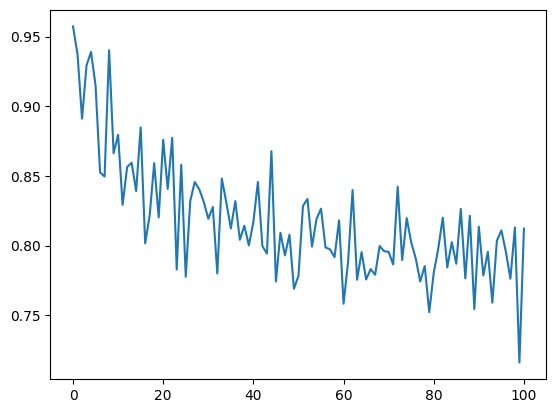

In [22]:
try:
    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    plt.plot(trainer.loss['epoch.train'][0])
except:
    traceback.print_exc()

In [ ]:
try:
    print(trainer.timer.timers.keys())
    print(trainer.timer.timers['train'].average)
    print(trainer.timer.timers['train_dataloader'].average)
    print(trainer.timer.timers['_train_step'].average)
    print(trainer.timer.timers['batch'].average)
except:
    traceback.print_exc()

In [45]:
try:
    print(type(abc[0][0]))
    print(type(abc[0][1]))
    print(type(abc[0][2]))
    print(type(abc[0][3]))
    print(type(abc[0][4]))
    print(type(abc[0][5]))
    print(type(abc[1][0]))
    print(type(abc[1][1]))

    print(abc[0][1].dtype)
    print(abc[0][3].dtype)
    print(abc[0][5].dtype)
except:
    traceback.print_exc()

<class 'numpy.int64'>
<class 'numpy.ndarray'>
<class 'numpy.int64'>
<class 'numpy.ndarray'>
<class 'numpy.int64'>
<class 'numpy.ndarray'>
<class 'numpy.float64'>
<class 'numpy.float64'>
float32
float32
float32


In [27]:
try:
    sss = data_model.user_features.iloc[1].astype(int).to_numpy()
    print(sss)
    print(sss.dtype)
except:
    traceback.print_exc()

[0 1 0 ... 1 1 5]
int64


In [97]:
try:
    print(len(ds))
except:
    traceback.print_exc()

4670209
